In [2]:
import os
import sys
import pandas as pd

In [3]:
input_dir = '../1_inputs'
output_dir = '../3_outputs'

In [4]:
allele_collection_df = pd.read_csv(f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores.tsv', sep='\t')
allele_collection_df

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37629/185101264.py:1: DtypeWarning: Columns (99,101,134,137,153,154,156,157,159,161,185,186,188,189,191,192,195,206,213,214,226,227,237,238,239,250,251,254,255) have mixed types. Specify dtype option on import or set low_memory=False.
  allele_collection_df = pd.read_csv(f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores.tsv', sep='\t')


,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,SCV000232587|SCV000321701|SCV000893215|SCV0009...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,98.91,0.225806
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,SCV000111209|SCV000491300|SCV000692643|SCV0006...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,98.39,0.097561
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,SCV000697586|SCV001422687|SCV001713036|SCV0020...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,98.35,0.052419
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7936,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,SCV000513395,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,93.30,0.500000
7937,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,SCV000589376|SCV002011544|SCV002512603|SCV0025...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,88.17,0.443548
7938,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,SCV000513398,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,97.95,0.705645
7939,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,SCV001583928|SCV002074112|SCV002655406,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,70.32,0.838710


In [5]:
# Extract OMIM data from PhenotypeIDS and store in OMIM_IDs column
allele_collection_df['OMIM_IDs'] = allele_collection_df['PhenotypeIDS'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)

allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,98.91,0.225806,"[608013, 230800, 230900, 231000, 231005, 16860..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,98.39,0.097561,"[230900, 230800, 231000, 168600, 608013, 23080..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,98.35,0.052419,"[230800, 127750, 168600]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7936,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,93.30,0.500000,[314580]
7937,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,88.17,0.443548,"[314580, 301041]"
7938,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,97.95,0.705645,[314580]
7939,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,70.32,0.838710,[314580]


In [6]:
# Load inheritance mapping from previously generated file
inheritance_df = pd.read_csv(f'{output_dir}/inheritance_mapping.csv')
inheritance_dict = inheritance_df.set_index(['orf_id', 'nt_change', 'aa_change'])['inheritance_clean'].to_dict()

print(f"Loaded {len(inheritance_dict)} inheritance mappings")
print("Inheritance patterns found:")
print(inheritance_df['inheritance_clean'].value_counts())

Loaded 8488 inheritance mappings
Inheritance patterns found:
inheritance_clean
autosomal recessive    3050
autosomal dominant     2008
multiple                683
x-linked recessive      351
x-linked                 79
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   4
multifactorial            3
digenic recessive         2
unclear phenotype         1
somatic mutation          1
Name: count, dtype: int64


In [7]:
# Load disease modules mapping from previously generated file
disease_modules_df = pd.read_csv(f'{output_dir}/disease_modules_to_genes.tsv', sep='\t')

# Create a mapping from gene symbol to disease modules
gene_to_modules = {}
for _, row in disease_modules_df.iterrows():
    if pd.notna(row['genes']) and row['genes']:  # Check if genes column is not empty
        gene_list = row['genes'].split(';')
        for gene in gene_list:
            if gene not in gene_to_modules:
                gene_to_modules[gene] = []
            gene_to_modules[gene].append(row['disease_module'])

print(f"Loaded {len(disease_modules_df)} disease modules")
print(f"Mapped {len(gene_to_modules)} genes to disease modules")
print("Disease modules:")
print(disease_modules_df['disease_module'].tolist())

Loaded 28 disease modules
Mapped 1276 genes to disease modules
Disease modules:
['Rare genetic vascular disease', 'Rare genetic systemic or rheumatologic disease', 'Rare genetic eye disease', 'Rare genetic gynecological and obstetrical diseases', 'Rare genetic immune disease', 'Rare genetic cardiac disease', 'Rare genetic renal disease', 'Rare genetic developmental defect during embryogenesis', 'Rare genetic bone disease', 'Rare genetic odontologic disease', 'Rare genetic hematologic disease', 'Laminopathy', 'Ciliopathy', 'Genetic otorhinolaryngologic disease', 'Rare genetic urogenital disease', 'Rare genetic respiratory disease', 'Rare genetic hepatic disease', 'Rare genetic endocrine disease', 'Rare genetic neurological disorder', 'RASopathy', 'Serpinopathy', 'Rare genetic gastroenterological disease', 'Rare inborn errors of metabolism', 'Genetic infertility', 'Rare genetic skin disease', 'Rare chromosomal anomaly', 'Rare genetic tumor', 'Inherited cancer-predisposing syndrome']


In [8]:
# Load OMIM data to get disease names
omim_df = pd.read_csv(f'{input_dir}/mimTitles.txt', sep="\t", skiprows=2)
omim_df.dropna(subset=['MIM Number'], inplace=True)
omim_df['MIM Number'] = omim_df['MIM Number'].astype(int)
omim_df['disease_name'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[0])
omim_df['Symbol'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[-1] if ';' in x else None)
omim_df.drop(columns=['Preferred Title; symbol'], inplace=True)

# Create mapping dictionary from OMIM ID to disease name
omim_id_to_name = omim_df.set_index('MIM Number')['disease_name'].to_dict()

print(f"Loaded {len(omim_id_to_name)} OMIM disease names")
print("Sample OMIM mappings:")
for i, (omim_id, name) in enumerate(list(omim_id_to_name.items())[:5]):
    print(f"  {omim_id}: {name}")
print("...")

Loaded 29102 OMIM disease names
Sample OMIM mappings:
  100050: AARSKOG SYNDROME, AUTOSOMAL DOMINANT
  100070: AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1
  100100: PRUNE BELLY SYNDROME
  100200: ABDUCENS PALSY
  100300: ADAMS-OLIVER SYNDROME 1
...


In [9]:
# Map inheritance patterns to the allele collection dataframe
allele_collection_df['inheritance_pattern'] = None

for i, row in allele_collection_df.iterrows():
    # Create key for inheritance mapping
    key = (row['orf_id'], row['nt_change'], row['aa_change'])
    if key in inheritance_dict:
        allele_collection_df.at[i, 'inheritance_pattern'] = inheritance_dict[key]

print("Inheritance mapping results:")
print(allele_collection_df['inheritance_pattern'].value_counts(dropna=False))

Inheritance mapping results:
inheritance_pattern
autosomal recessive    2719
NaN                    1993
autosomal dominant     1805
multiple                630
x-linked recessive      343
None                    288
x-linked                 73
x-linked dominant        63
unknown                   8
y-linked                  6
somatic                   4
common variant            3
digenic recessive         2
multifactorial            2
unclear phenotype         1
somatic mutation          1
Name: count, dtype: int64

inheritance_pattern
autosomal recessive    2719
NaN                    1993
autosomal dominant     1805
multiple                630
x-linked recessive      343
None                    288
x-linked                 73
x-linked dominant        63
unknown                   8
y-linked                  6
somatic                   4
common variant            3
digenic recessive         2
multifactorial            2
unclear phenotype         1
somatic mutation          1
Name: co

In [10]:
# Map disease modules to the allele collection dataframe
allele_collection_df['disease_modules'] = None
allele_collection_df['disease_module_count'] = 0

for i, row in allele_collection_df.iterrows():
    if pd.notna(row['symbol']) and row['symbol'] in gene_to_modules:
        modules = gene_to_modules[row['symbol']]
        allele_collection_df.at[i, 'disease_modules'] = '; '.join(modules)
        allele_collection_df.at[i, 'disease_module_count'] = len(modules)

print("Disease module mapping results:")
print(f"Genes with disease modules: {allele_collection_df['disease_module_count'].gt(0).sum()}")
print(f"Genes without disease modules: {allele_collection_df['disease_module_count'].eq(0).sum()}")
print("\nDisease module count distribution:")
print(allele_collection_df['disease_module_count'].value_counts().sort_index())

Disease module mapping results:
Genes with disease modules: 7072
Genes without disease modules: 869

Disease module count distribution:
disease_module_count
0      869
1     1357
2     1872
3     1483
4      815
5      468
6      271
7      456
8      171
9       56
10      12
11      73
12       9
13      29
Name: count, dtype: int64

Genes with disease modules: 7072
Genes without disease modules: 869

Disease module count distribution:
disease_module_count
0      869
1     1357
2     1872
3     1483
4      815
5      468
6      271
7      456
8      171
9       56
10      12
11      73
12       9
13      29
Name: count, dtype: int64


In [11]:
# Map OMIM disease names to the allele collection dataframe
allele_collection_df['OMIM_disease_names'] = None

for i, row in allele_collection_df.iterrows():
    omim_ids = row['OMIM_IDs']
    if isinstance(omim_ids, list) and len(omim_ids) > 0:
        disease_names = []
        for omim_id in omim_ids:
            omim_int = int(omim_id)
            if omim_int in omim_id_to_name:
                disease_names.append(omim_id_to_name[omim_int])
            else:
                disease_names.append(f"OMIM:{omim_id} (name not found)")
        allele_collection_df.at[i, 'OMIM_disease_names'] = '; '.join(disease_names)

print("OMIM disease name mapping results:")
print(f"Variants with OMIM disease names: {allele_collection_df['OMIM_disease_names'].notna().sum()}")
print(f"Variants without OMIM disease names: {allele_collection_df['OMIM_disease_names'].isna().sum()}")

# Show some examples
print("\nExamples of OMIM disease name mappings:")
sample_data = allele_collection_df[allele_collection_df['OMIM_disease_names'].notna()][['symbol', 'OMIM_IDs', 'OMIM_disease_names']].head(5)
for _, row in sample_data.iterrows():
    print(f"  {row['symbol']}: {row['OMIM_disease_names']}")

OMIM disease name mapping results:
Variants with OMIM disease names: 5943
Variants without OMIM disease names: 1998

Examples of OMIM disease name mappings:

Variants with OMIM disease names: 5943
Variants without OMIM disease names: 1998

Examples of OMIM disease name mappings:
  GBA1: GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYPE III; GAUCHER DISEASE, TYPE IIIC; PARKINSON DISEASE, LATE-ONSET; GAUCHER DISEASE, TYPE I
  GBA1: GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE III; PARKINSON DISEASE, LATE-ONSET; GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYPE III; GAUCHER DISEASE, TYPE IIIC; DEMENTIA, LEWY BODY
  GBA1: GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; PARKINSON DISEASE, LATE-ONSET
  GBA1: GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DISEASE, TYPE IIIC; GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE II; GAUCHER

In [12]:
# Summary statistics of the enhanced dataframe
print("=== MAPPING SUMMARY ===")
print(f"Total variants: {len(allele_collection_df)}")
print(f"Variants with OMIM IDs: {allele_collection_df['OMIM_IDs'].notna().sum()}")
print(f"Variants with OMIM disease names: {allele_collection_df['OMIM_disease_names'].notna().sum()}")
print(f"Variants with inheritance patterns: {allele_collection_df['inheritance_pattern'].notna().sum()}")
print(f"Variants with disease modules: {allele_collection_df['disease_modules'].notna().sum()}")

print("\n=== INHERITANCE PATTERNS ===")
print(allele_collection_df['inheritance_pattern'].value_counts(dropna=False))

print("\n=== DISEASE MODULES COVERAGE ===")
for module in disease_modules_df['disease_module'].tolist():
    count = allele_collection_df['disease_modules'].str.contains(module, na=False).sum()
    print(f"{module}: {count} variants")

# Display the enhanced dataframe
print("\n=== ENHANCED DATAFRAME ===")
allele_collection_df[['symbol', 'aa_change', 'OMIM_IDs', 'OMIM_disease_names', 'inheritance_pattern', 'disease_modules', 'disease_module_count']].head(10)

=== MAPPING SUMMARY ===
Total variants: 7941
Variants with OMIM IDs: 5943
Variants with OMIM disease names: 5943
Variants with inheritance patterns: 5660
Variants with disease modules: 7072

=== INHERITANCE PATTERNS ===
inheritance_pattern
autosomal recessive    2719
NaN                    1993
autosomal dominant     1805
multiple                630
x-linked recessive      343
None                    288
x-linked                 73
x-linked dominant        63
unknown                   8
y-linked                  6
somatic                   4
common variant            3
digenic recessive         2
multifactorial            2
unclear phenotype         1
somatic mutation          1
Name: count, dtype: int64

=== DISEASE MODULES COVERAGE ===
Rare genetic vascular disease: 109 variants
Rare genetic systemic or rheumatologic disease: 226 variants
Rare genetic eye disease: 2462 variants
Rare genetic gynecological and obstetrical diseases: 481 variants
Rare genetic immune disease: 566 variants

,symbol,aa_change,OMIM_IDs,OMIM_disease_names,inheritance_pattern,disease_modules,disease_module_count
0,GBA1,Val54Leu,NaN,None,NaN,None,0
1,GBA1,Leu224Phe,NaN,None,NaN,None,0
2,GBA1,Arg296Gln,"[608013, 230800, 230900, 231000, 231005, 16860...","GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS...",multiple,None,0
3,GBA1,Leu483Pro,"[230900, 230800, 231000, 168600, 608013, 23080...","GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP...",multiple,None,0
4,GBA1,Arg87Trp,"[230800, 127750, 168600]","GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ...",multiple,None,0
5,GBA1,Arg159Gln,"[230800, 608013, 231005, 230800, 230900, 231000]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, PERI...",autosomal recessive,None,0
6,GBA1,Lys196Gln,[230800],"GAUCHER DISEASE, TYPE I",autosomal recessive,None,0
7,GBA1,Arg209Cys,"[230800, 230900, 231005, 231000, 230800]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE...",autosomal recessive,None,0
8,GBA1,Trp223Arg,"[230800, 230900, 231000]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE...",autosomal recessive,None,0
9,GBA1,Arg202Gln,NaN,None,NaN,None,0


In [13]:
# Save the enhanced dataframe with OMIM, inheritance, and disease module mappings
output_filename = f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv'
allele_collection_df.to_csv(output_filename, sep='\t', index=False)

print(f"Enhanced allele collection saved to: {output_filename}")
print(f"Added columns: OMIM_IDs, OMIM_disease_names, inheritance_pattern, disease_modules, disease_module_count")

# Display final dataframe
allele_collection_df

Enhanced allele collection saved to: ../3_outputs/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv
Added columns: OMIM_IDs, OMIM_disease_names, inheritance_pattern, disease_modules, disease_module_count


,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,0,None
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,0,None
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,NM_000157.4,2.0,1_Pathogenic,98.91,0.225806,"[608013, 230800, 230900, 231000, 231005, 16860...",multiple,None,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,NM_000157.4,2.0,1_Pathogenic,98.39,0.097561,"[230900, 230800, 231000, 168600, 608013, 23080...",multiple,None,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,NM_000157.4,2.0,1_Pathogenic,98.35,0.052419,"[230800, 127750, 168600]",multiple,None,0,"GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7936,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,NM_018684.4,NaN,1_Pathogenic,93.30,0.500000,[314580],None,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME
7937,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,NM_018684.4,2.0,1_Pathogenic,88.17,0.443548,"[314580, 301041]",None,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME; WIEACKER-WOLFF SYNDRO...
7938,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,NM_018684.4,NaN,1_Pathogenic,97.95,0.705645,[314580],None,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME
7939,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,NM_018684.4,2.0,1_Pathogenic,70.32,0.838710,[314580],None,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME


In [14]:
allele_collection_df.clinvar_clnsig_clean.value_counts(dropna=False)

clinvar_clnsig_clean
1_Pathogenic     4142
4_VUS            1005
3_Conflicting     967
NaN               840
2_Benign          598
5_Others          389
Name: count, dtype: int64

In [ ]:
allele_collection_df.plddt.value_counts(dropna=False)

plddt
NaN      1045
98.76      38
98.89      37
98.84      36
98.88      35
         ... 
75.40       1
62.48       1
45.81       1
33.86       1
78.85       1
Name: count, Length: 2291, dtype: int64

In [56]:
allele_collection_df.plddt

# Drop NaN values before binning
plddt_values = allele_collection_df['plddt'].dropna()

# Define bins and labels
bins = list(range(0, 111, 10))
labels = [f"{i}-{i+10}" for i in range(0, 101, 10)]

# Bin the values
plddt_binned = pd.cut(plddt_values, bins=bins, right=False, labels=labels)

# Count occurrences in each bin
plddt_bin_counts = plddt_binned.value_counts().sort_index()
print(plddt_bin_counts)

print(f"\nTotal RSA values: {len(plddt_values)}")
print(f"Total binned: {plddt_bin_counts.sum()}")
print(f"Missing: {len(plddt_values) - plddt_bin_counts.sum()}")

plddt
0-10          0
10-20         1
20-30        65
30-40       208
40-50       220
50-60       192
60-70       199
70-80       284
80-90       853
90-100     4874
100-110       0
Name: count, dtype: int64

Total RSA values: 6896
Total binned: 6896
Missing: 0


In [53]:
allele_collection_df.rsa

# Drop NaN values before binning
rsa_values = allele_collection_df['rsa'].dropna() * 100

# Define bins and labels - extend to 101 to include 100%
bins = list(range(0, 111, 10))  # Goes to 110 to include 100-110 bin
labels = [f"{i}-{i+10}" for i in range(0, 101, 10)]  # Include 100-110 label

# Bin the values
rsa_binned = pd.cut(rsa_values, bins=bins, right=False, labels=labels)

# Count occurrences in each bin
rsa_bins_counts = rsa_binned.value_counts().sort_index()
print(rsa_bins_counts)

# Check if we're missing any values
print(f"\nTotal RSA values: {len(rsa_values)}")
print(f"Total binned: {rsa_bins_counts.sum()}")
print(f"Missing: {len(rsa_values) - rsa_bins_counts.sum()}")

rsa
0-10       2577
10-20       771
20-30       580
30-40       496
40-50       494
50-60       507
60-70       414
70-80       322
80-90       334
90-100      270
100-110     131
Name: count, dtype: int64

Total RSA values: 6896
Total binned: 6896
Missing: 0


In [47]:
rsa_bins_counts.sum()

6765

In [52]:
allele_collection_df.rsa.value_counts().sum()

6896

In [17]:
allele_collection_df.inheritance_pattern.value_counts(dropna=False)

inheritance_pattern
autosomal recessive    2719
NaN                    1993
autosomal dominant     1805
multiple                630
x-linked recessive      343
None                    288
x-linked                 73
x-linked dominant        63
unknown                   8
y-linked                  6
somatic                   4
common variant            3
digenic recessive         2
multifactorial            2
unclear phenotype         1
somatic mutation          1
Name: count, dtype: int64

In [18]:
allele_collection_df.disease_modules.value_counts(dropna=False)

disease_modules
None                                                                                                                                                                                  869
Rare genetic neurological disorder                                                                                                                                                    354
Rare genetic cardiac disease; Rare genetic neurological disorder                                                                                                                      332
Rare genetic neurological disorder; Rare inborn errors of metabolism                                                                                                                  289
Rare genetic hematologic disease                                                                                                                                                      277
                                                      

In [19]:
allele_collection_df[[c for c in allele_collection_df.columns if 'gnomad' in c.lower()]]

,gnomad_af,gnomAD2.1.1_exomes_flag,gnomAD2.1.1_exomes_controls_AC,gnomAD2.1.1_exomes_controls_AN,gnomAD2.1.1_exomes_controls_AF,gnomAD2.1.1_exomes_controls_nhomalt,gnomAD2.1.1_exomes_non_neuro_AC,gnomAD2.1.1_exomes_non_neuro_AN,gnomAD2.1.1_exomes_non_neuro_AF,gnomAD2.1.1_exomes_non_neuro_nhomalt,...,gnomAD4.1_joint_MID_AF,gnomAD4.1_joint_MID_nhomalt,gnomAD4.1_joint_NFE_AC,gnomAD4.1_joint_NFE_AN,gnomAD4.1_joint_NFE_AF,gnomAD4.1_joint_NFE_nhomalt,gnomAD4.1_joint_SAS_AC,gnomAD4.1_joint_SAS_AN,gnomAD4.1_joint_SAS_AF,gnomAD4.1_joint_SAS_nhomalt
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.000078,segdup,3,109406,2.742080e-05,0,7,208120,3.363440e-05,0,...,0.000000e+00,0,114,1179874,9.662050e-05,0,0,91078,0.000000e+00,0
3,0.000084,segdup,145,108986,1.330450e-03,0,265,207224,1.278810e-03,0,...,.,.,.,.,.,.,.,.,.,.
4,0.000012,segdup,3,109372,2.742930e-05,0,6,207980,2.884890e-05,0,...,1.650170e-04,0,10,1180008,8.474520e-06,0,2,91086,2.195730e-05,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7936,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.
7937,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.
7938,NaN,.,.,.,.,.,.,.,.,.,...,0.000000e+00,0,0,894933,0.000000e+00,0,0,56759,0.000000e+00,0
7939,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.


In [57]:
# Count allele frequencies based on gnomad_af, except for singletons and 2-10 alleles
singletons = 0
two_ten_alleles = 0
zerzerooneperc = 0
zerooneperc = 0
oneperc = 0
morethan10perc = 0
counted_alleles = []


for i, row in allele_collection_df.iterrows():
    if pd.isna(row['gnomAD4.1_joint_AC']):
        continue
    if row['gnomAD4.1_joint_AC'] == 0 or row['gnomAD4.1_joint_AC'] == '.':  # No alleles
        continue
    if int(row['gnomAD4.1_joint_AC']) == 1:  # Singleton
        singletons += 1
        counted_alleles.append(i)
    elif 2 <= int(row['gnomAD4.1_joint_AC']) <= 10:  # 2-10 alleles
        two_ten_alleles += 1
        counted_alleles.append(i)
        
for i, row in allele_collection_df.iterrows():        
    if i in counted_alleles:  # Skip already counted singletons and 2-10 alleles
        continue
    if pd.isna(row['gnomad_af']):
        continue
    elif row['gnomad_af'] < 0.01:  # <0.001%
        zerzerooneperc += 1
    elif row['gnomad_af'] < 0.1:  # <0.01%
        zerooneperc += 1
    elif row['gnomad_af'] < 1:  # <0.1%
        oneperc += 1
    else:  # >10%
        morethan10perc += 1

print(f"Singletons: {singletons}")
print(f"2-10 alleles: {two_ten_alleles}")
print(f"<0.01%: {zerzerooneperc}")
print(f"<0.1%: {zerooneperc}")
print(f"<1%: {oneperc}")
print(f">1%: {morethan10perc}")

Singletons: 510
2-10 alleles: 1104
<0.01%: 2835
<0.1%: 191
<1%: 160
>1%: 0


In [21]:
allele_collection_df[allele_collection_df['gnomAD4.1_joint_AC'] == '1'][['gnomad_af']]

,gnomad_af
14,6.841580e-07
18,NaN
46,6.990040e-07
54,NaN
102,6.845810e-07
...,...
7815,NaN
7833,NaN
7885,6.842630e-07
7898,NaN


In [22]:
disease_modules_count_dict = {}

for i, row in allele_collection_df.iterrows():
    disease_modules = row.disease_modules
    if disease_modules is not None and pd.notna(disease_modules):
        disease_modules_list = disease_modules.split('; ')
        for module in disease_modules_list:
            if module not in disease_modules_count_dict:
                disease_modules_count_dict[module] = 0
            disease_modules_count_dict[module] += 1
            
            
disease_modules_count_dict

{'Rare genetic developmental defect during embryogenesis': 2569,
 'Rare inborn errors of metabolism': 2586,
 'Rare genetic neurological disorder': 3312,
 'Rare genetic eye disease': 2462,
 'Rare genetic bone disease': 904,
 'Rare genetic immune disease': 566,
 'Rare genetic vascular disease': 109,
 'Rare genetic systemic or rheumatologic disease': 226,
 'Rare genetic gastroenterological disease': 478,
 'Rare genetic hematologic disease': 748,
 'Rare genetic skin disease': 1385,
 'Rare genetic gynecological and obstetrical diseases': 481,
 'Rare genetic renal disease': 1310,
 'Rare genetic hepatic disease': 478,
 'Rare genetic endocrine disease': 1275,
 'Genetic infertility': 621,
 'Serpinopathy': 49,
 'Rare genetic urogenital disease': 181,
 'Ciliopathy': 287,
 'Rare genetic tumor': 584,
 'Inherited cancer-predisposing syndrome': 704,
 'Genetic otorhinolaryngologic disease': 471,
 'Rare genetic cardiac disease': 919,
 'RASopathy': 133,
 'Rare chromosomal anomaly': 158,
 'Rare genetic o

In [34]:
# import rare disease module file
# from https://www.nature.com/articles/s41467-021-26674-1
# supplementary data 5

rd_df = pd.read_csv(f'{input_dir}/rare_disease_modules.txt', sep='\t')

# Add a column with the gene count for each module in rd_df
rd_df['gene_count'] = rd_df['all_genes'].apply(lambda x: len(x.split(';')) if pd.notna(x) and x else 0)
rd_df.to_csv(f'{output_dir}/rare_disease_modules_ALL_GENES_with_gene_count.tsv', sep='\t', index=False)


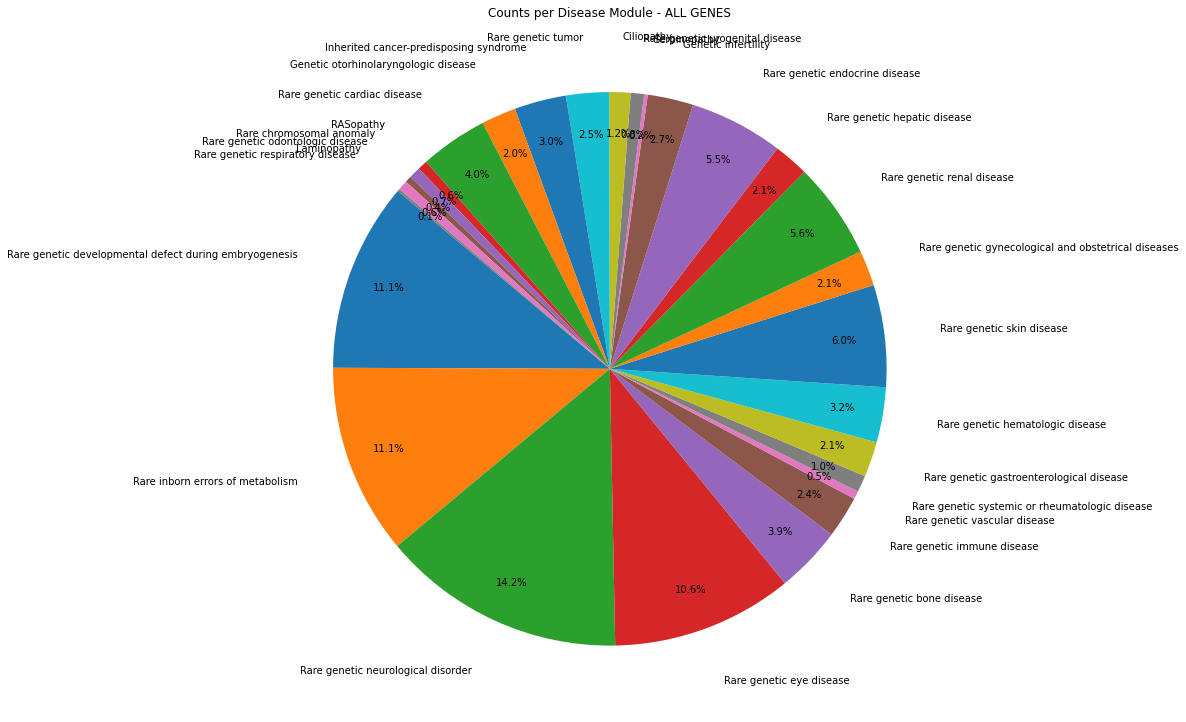

In [40]:
import matplotlib.pyplot as plt

# Pie chart for counts per module using disease_modules_count_dict
labels = list(disease_modules_count_dict.keys())
sizes = list(disease_modules_count_dict.values())

plt.figure(figsize=(16, 16))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, labeldistance=1.2, pctdistance=0.85)
plt.title('Counts per Disease Module - ALL GENES')
plt.tight_layout()
plt.show()
